# Slezak et al. (2018): a silica microsphere in a magneto-gravitational trap

B. R. Slezak, C. W. Lewandowski, J.-F. Hsu and B. D'Urso, *Cooling the motion of a silica microsphere in
a magneto-gravitational trap in ultra-high vacuum*, New J. Phys. **20**, 063028 (2018),
[doi:10.1088/1367-2630/aacac1](https://doi.org/10.1088/1367-2630/aacac1).

A silica microsphere (mean diameter 1.54 μm) is held by the diamagnetic force of the field between four
ferromagnetic pole pieces, driven by two SmCo magnets, together with gravity. The paper models the field
by the three lowest non-zero multipoles of the magnetic scalar potential, with the coefficients chosen to
match the measured frequencies, following its predecessor Hsu et al., Sci. Rep. **6**, 30125 (2016),
[doi:10.1038/srep30125](https://doi.org/10.1038/srep30125), which writes the expansion out (Eq. (1)-(4))
and states its fitted coefficients. levisim's `MultipoleField` uses exactly that normalisation, and
`MagneticTrap` the energy $U = -(V/2\mu_0)\,\mathbf{B}\cdot\chi\,\mathbf{B} + mgy$ (Slezak Eq. (1)).

**How the pole-piece geometry is approximated.** Neither paper gives the pole-piece dimensions, so the
field is not computed from the magnets: it is the paper's own local model, the quadrupole $(2,-2)$,
hexapole $(3,1)$ and octupole $(4,-4)$ solid harmonics about the trap centre with reference radius
$y_0$ = 75 μm (the centre-to-pole distance stated by Hsu et al.; Slezak et al. do not state theirs, and
the choice only rescales the fitted coefficients). The model is valid near the centre only, not at the
pole pieces.

**What is compared, stated before running:**

1. The levitation condition $B\,\partial B/\partial y = \mu_0\rho g/|\chi|$ against Table 1 of Houlton
   et al., Rev. Sci. Instrum. **89**, 125107 (2018), [doi:10.1063/1.5051667](https://doi.org/10.1063/1.5051667)
   (same group): H₂O 1360, SiO₂ 2400, GaN 3710, graphite 1990, mineral oil 1230 T²/m.
2. The field model: Hsu et al.'s published coefficients ($a_2$ = −1.3 T, $a_3$ = 0.018 T, $a_4$ = 0.72 T)
   must give their published $\omega/2\pi$ = (104, 130, 9.6) Hz, $y_\mathrm{eq}$ = −19 μm and
   $B_\mathrm{eq} \approx$ 0.2 T for diamond.
3. Slezak et al.: the frequencies of a single-quadrupole trap with the stated gradient "∼10⁴ T/m" against
   the measured $\omega/2\pi$ = (59.6, 96.9, 7.01) Hz; then the three-multipole fit to those frequencies,
   whose gradient must be of order 10⁴ T/m; the frequencies' independence of particle size.
4. The mass of a 1.54 μm silica sphere against the measured (3.10 ± 0.05) × 10⁻¹⁵ kg and the paper's
   expected (3.4 ± 1.0) × 10⁻¹⁵ kg.
5. The gas damping at ∼10⁻¹⁰ Torr against the paper's estimate Γ/2π = 2 × 10⁻⁸ Hz (Epstein).
6. A time-domain simulation (`FreeSpaceSimulation` with `MagneticTrap` + `Gravity`): the PSD peaks against
   the stiffness at the equilibrium.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| frequencies $\omega_{x,y,z}/2\pi$ | 59.6, 96.9, 7.01 Hz | Slezak Sec. 2.1 |
| diameter | 1.54 μm (CV 9.6 %) | Slezak Sec. 2.2 (Cospheric SiO2MS-1.8) |
| mass | (3.10 ± 0.05) × 10⁻¹⁵ kg measured | Slezak Sec. 2.3 |
| silica $\rho$, $\chi$ | 2200 kg/m³, −11.28 × 10⁻⁶ | Houlton et al. (2018) Table 1 (`FUSED_SILICA` has the same χ) |
| gravity | 9.80665 m/s² along −y (y vertical, z axial, x transverse) | Slezak Fig. 2 axes |
| field model | multipoles (2,−2), (3,1), (4,−4), $y_0$ = 75 μm | Hsu et al. Eq. (1)-(4); $y_0$ **assumed** from Hsu |
| pressure | ∼10⁻¹⁰ Torr (UHV) | Slezak Sec. 4 |
| diamond (check 2) | ρ = 3510 kg/m³, χ = −2.2 × 10⁻⁵ | **assumed** (not stated by Hsu et al.) |

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import least_squares
from scipy.signal import welch

from levisim.core.constants import μ0
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import Hz, mbar, μm
from levisim.physics import Sphere, Trap
from levisim.physics.fields import Gravity, MagneticTrap, MultipoleField
from levisim.physics.gas import Gas
from levisim.physics.materials import FUSED_SILICA
from levisim.simulation import FreeSpaceSimulation

set_plt_rcParams_to_xmgrace_style()
t_start = time.time()
g = 9.80665
Torr = 1.33322 * mbar
ω_paper = np.array([59.6, 96.9, 7.01]) * Hz
silica = FUSED_SILICA.replace(ρ=2200.0)       # χ_m = -11.28e-6 (Houlton et al. 2018, Table 1)
sphere = Sphere(r=1.54 * μm / 2, material=silica)
print(f'χ = {silica.χ_m:.4g}, ρ = {silica.ρ} kg/m³, m(1.54 μm) = {sphere.m:.3e} kg')

χ = -1.128e-05, ρ = 2200.0 kg/m³, m(1.54 μm) = 4.207e-15 kg


## 1. Levitation condition against Houlton et al. (2018), Table 1

`MagneticTrap.required_B_gradB` is $\mu_0\rho g/|\chi_\mathrm{eff}|$; with `shape_correction=False` it uses
the bare χ, as the table does (the demagnetising correction of a sphere changes it by $|\chi|/3 \sim 10^{-5}$).

In [2]:
from levisim.physics import Material
from levisim.physics.fields import LocalFieldExpansion
table = {  # ρ [kg/m³], χ, published (B∇B)_z [T²/m]
    'H2O': (1000, -9.05e-6, 1360), 'SiO2': (2200, -11.28e-6, 2400), 'GaN': (6150, -20.4e-6, 3710),
    'graphite': (2270, -14e-6, 1990), 'mineral oil': (878, -8.8e-6, 1230),
}
probe = LocalFieldExpansion(B0=(0, 1, 0))
for name, (ρ, χ, published) in table.items():
    p = Sphere(r=1 * μm, material=Material(name, ρ, χ_m=χ))
    bare = MagneticTrap(probe, shape_correction=False).required_B_gradB(p, g=g)
    corrected = MagneticTrap(probe).required_B_gradB(p, g=g)
    print(f'{name:12s} levisim {bare:7.1f} T²/m (shape-corrected {corrected:7.1f}), published {published}, '
          f'ratio {bare / published:.4f}')

H2O          levisim  1361.7 T²/m (shape-corrected  1361.7), published 1360, ratio 1.0013
SiO2         levisim  2403.5 T²/m (shape-corrected  2403.5), published 2400, ratio 1.0015
GaN          levisim  3715.1 T²/m (shape-corrected  3715.1), published 3710, ratio 1.0014
graphite     levisim  1998.2 T²/m (shape-corrected  1998.1), published 1990, ratio 1.0041
mineral oil  levisim  1229.5 T²/m (shape-corrected  1229.5), published 1230, ratio 0.9996


## 2. The field model: Hsu et al. (2016) forward check

With their published coefficients (two significant figures) and the assumed diamond χ and ρ, the report
of the `Trap` gives the equilibrium below the field zero and the three frequencies.

In [3]:
diamond = Material('diamond (assumed χ)', 3510.0, χ_m=-2.2e-5)
hsu = MultipoleField({(2, -2): -1.3, (3, 1): 0.018, (4, -4): 0.72}, r0=75 * μm)
hsu_trap = Trap(fields=[MagneticTrap(hsu, shape_correction=False), Gravity(g=g, direction=(0, -1, 0))],
                particle=Sphere(r=0.5 * μm, material=diamond))
rep = hsu_trap.magnetic_trap_report(r_guess=(0, -1 * μm, 0))
print(hsu_trap.magnetic_trap_report_str(r_guess=(0, -1 * μm, 0)))
print('published: ω/2π = (104, 130, 9.6) Hz, y_eq = -19 μm, B_eq ≈ 0.2 T')
print('ratios ω/ω_paper:', np.round(rep['Ω_axes'] / (np.array([104, 130, 9.6]) * Hz), 4))

  equilibrium = [  0.     -18.8667   0.    ] μm
  |B| = 0.1856 T, χ_eff along B = -2.2e-05
  levitation: B∂B/∂h = 1966.1 T²/m (needed 1966.1 T²/m), margin = 33.82
  Ω_axes/2π = [106.14609 130.32436   9.56429] Hz
  normal modes Ω/2π = [  9.56429 106.14609 130.32436] Hz, stable = True
  trap depth ≈ 1.922e-20 J = 1392 K·kB (lower bound)
published: ω/2π = (104, 130, 9.6) Hz, y_eq = -19 μm, B_eq ≈ 0.2 T
ratios ω/ω_paper: [1.0206 1.0025 0.9963]


## 3. Slezak et al.: the stated gradient, then the fitted field

For a pure linear quadrupole $|\mathbf{B}| = G\rho$ the potential is harmonic with
$\omega^2 = |\chi| G^2/(\mu_0 \rho_m)$ in both transverse directions, and gravity shifts the particle
down by $g/\omega^2$. With the paper's "∼10⁴ T/m":

In [4]:
G = 1e4
ω_quad = G * np.sqrt(abs(silica.χ_m) / (μ0 * silica.ρ))
print(f'pure quadrupole, G = 1e4 T/m: ω/2π = {ω_quad / Hz:.1f} Hz, sag g/ω² = {g / ω_quad**2 / μm:.1f} μm')
print(f'measured: ω_x/2π = 59.6 Hz, ω_y/2π = 96.9 Hz  ->  G for these: '
      f'{ω_paper[0] / ω_quad * G:.3g}, {ω_paper[1] / ω_quad * G:.3g} T/m')

pure quadrupole, G = 1e4 T/m: ω/2π = 101.7 Hz, sag g/ω² = 24.0 μm
measured: ω_x/2π = 59.6 Hz, ω_y/2π = 96.9 Hz  ->  G for these: 5.86e+03, 9.53e+03 T/m


Now the paper's procedure: choose $a_2$, $a_3$, $a_4$ so that the trap frequencies at the equilibrium
(which the solver finds with gravity) equal the measured ones. The fit is exact by construction, so its
content is the coefficients, the gradient, the equilibrium and the field there.

In [5]:
def build(a, particle=sphere, shape_correction=False):
    source = MultipoleField({(2, -2): a[0], (3, 1): a[1], (4, -4): a[2]}, r0=75 * μm)
    return Trap(fields=[MagneticTrap(source, shape_correction=shape_correction),
                        Gravity(g=g, direction=(0, -1, 0))], particle=particle)


def residual(a):
    try:
        report = build(a).magnetic_trap_report(r_guess=(0, -1 * μm, 0))
        return report['Ω_axes'] / ω_paper - 1
    except Exception:
        return np.full(3, 10.0)


fit = least_squares(residual, [-1.3, 0.018, 0.72], x_scale=[1, 0.01, 0.5], xtol=1e-14, ftol=1e-14)
a2, a3, a4 = fit.x
trap = build(fit.x)
rep = trap.magnetic_trap_report(r_guess=(0, -1 * μm, 0))
print(f'a2 = {a2:.5f} T, a3 = {a3:.6f} T, a4 = {a4:.5f} T   (Hsu 2016 trap: -1.3, 0.018, 0.72 T)')
print(trap.magnetic_trap_report_str(r_guess=(0, -1 * μm, 0)))
src = trap.fields[0].source
print(f'|∇B| (largest singular value of J): {np.linalg.norm(src.gradB(np.zeros(3)), 2):.0f} T/m at the field zero, '
      f'{np.linalg.norm(rep["gradB"], 2):.0f} T/m at the equilibrium (paper: ~1e4 T/m)')
for start in ([-0.5, 0.0, 0.0], [-2.0, 0.05, 1.5]):
    other = least_squares(residual, start, x_scale=[1, 0.01, 0.5], xtol=1e-14, ftol=1e-14)
    print('fit from', start, '->', np.round(other.x, 6), ' max residual', f'{np.abs(other.fun).max():.1e}')

a2 = -0.79363 T, a3 = 0.007238 T, a4 = 0.22319 T   (Hsu 2016 trap: -1.3, 0.018, 0.72 T)
  equilibrium = [  0.     -46.6918   0.    ] μm
  |B| = 0.3032 T, χ_eff along B = -1.128e-05
  levitation: B∂B/∂h = 2403.5 T²/m (needed 2403.5 T²/m), margin = 11.03
  Ω_axes/2π = [59.6  96.9   7.01] Hz
  normal modes Ω/2π = [ 7.01 59.6  96.9 ] Hz, stable = True
  trap depth ≈ 2.312e-20 J = 1675 K·kB (lower bound)
|∇B| (largest singular value of J): 5780 T/m at the field zero, 7928 T/m at the equilibrium (paper: ~1e4 T/m)
fit from [-0.5, 0.0, 0.0] -> [-0.793625  0.007238  0.223192]  max residual 5.6e-12
fit from [-2.0, 0.05, 1.5] -> [-0.793625  0.007238  0.223192]  max residual 7.0e-11


The frequencies are independent of the particle size (Hsu Eq. (7)): the ±9.6 % spread of the diameter
changes nothing, and the sphere's demagnetising correction ($\chi_\mathrm{eff} = \chi/(1 + \chi/3)$)
changes them by less than 2 × 10⁻⁶:

In [6]:
for d in (1.54 * 0.904, 1.54, 1.54 * 1.096):
    t = build(fit.x, particle=Sphere(r=d * μm / 2, material=silica))
    print(f'd = {d:.3f} μm: ω/2π = {np.round(t.magnetic_trap_report(r_guess=(0, -1 * μm, 0))["Ω_axes"] / Hz, 9)} Hz')
corr = build(fit.x, shape_correction=True).magnetic_trap_report(r_guess=(0, -1 * μm, 0))
print('shape-corrected χ_eff: relative frequency change', (corr['Ω_axes'] / rep['Ω_axes'] - 1))

d = 1.392 μm: ω/2π = [59.6  96.9   7.01] Hz
d = 1.540 μm: ω/2π = [59.6  96.9   7.01] Hz
d = 1.688 μm: ω/2π = [59.6  96.9   7.01] Hz
shape-corrected χ_eff: relative frequency change [1.70994325e-06 3.47698231e-07 5.79472263e-07]


### The fitted field

$|\mathbf{B}|$ in the transverse plane $z = 0$ and in the axial plane $x = 0$, with the equilibrium
(cross); compare Slezak Fig. 1. The zero-field line curves upward with $|z|$, which, with gravity, gives
the axial confinement.

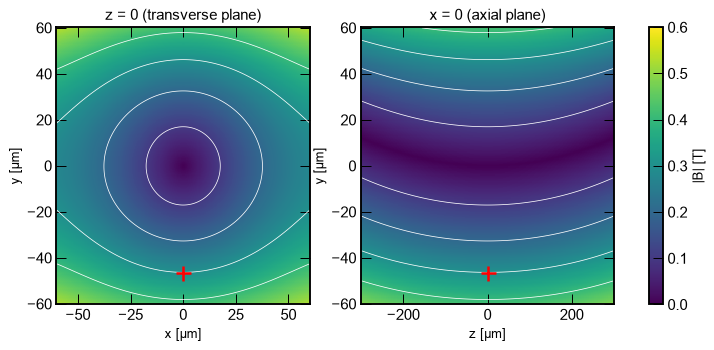

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
s = np.linspace(-60, 60, 241) * μm
X, Y = np.meshgrid(s, s)
B_xy = np.linalg.norm(src.B(np.stack([X, Y, 0 * X], -1)), axis=-1)
Z, Y2 = np.meshgrid(np.linspace(-300, 300, 241) * μm, s)
B_zy = np.linalg.norm(src.B(np.stack([0 * Z, Y2, Z], -1)), axis=-1)
for ax, (h, v, B, xl) in zip(axes, [(X, Y, B_xy, 'x [μm]'), (Z, Y2, B_zy, 'z [μm]')]):
    im = ax.pcolormesh(h / μm, v / μm, B, shading='auto', cmap='viridis', vmax=0.6)
    ax.contour(h / μm, v / μm, B, levels=[0.1, 0.2, 0.3, 0.4], colors='w', linewidths=0.6)
    ax.plot(0, rep['equilibrium'][1] / μm, 'r+', ms=12, mew=2)
    ax.set_xlabel(xl)
    ax.set_ylabel('y [μm]')
fig.colorbar(im, ax=axes, label='|B| [T]')
axes[0].set_title('z = 0 (transverse plane)')
axes[1].set_title('x = 0 (axial plane)')
plt.show()

## 4. Mass and 5. gas damping

In [8]:
m_measured = 3.10e-15
V = sphere.V
print(f'1.54 μm sphere: m = {sphere.m:.3e} kg at ρ = 2200; measured {m_measured:.2e} kg, paper expected (3.4 ± 1.0)e-15 kg')
print(f'densities implied: {m_measured / V:.0f} kg/m³ (measured mass), {3.4e-15 / V:.0f} kg/m³ (expected mass)')
for ρ in (2200.0, m_measured / V):
    t = Trap(fields=[MagneticTrap(src)], particle=Sphere(r=0.77 * μm, material=silica.replace(ρ=ρ)),
             gas=Gas(P=1e-10 * Torr, T=295.0))
    print(f'ρ = {ρ:.0f}: levisim gas damping Γ/2π = {t.Γth / Hz:.2e} Hz at 1e-10 Torr (paper estimate 2e-8 Hz)')

1.54 μm sphere: m = 4.207e-15 kg at ρ = 2200; measured 3.10e-15 kg, paper expected (3.4 ± 1.0)e-15 kg
densities implied: 1621 kg/m³ (measured mass), 1778 kg/m³ (expected mass)
ρ = 2200: levisim gas damping Γ/2π = 9.56e-09 Hz at 1e-10 Torr (paper estimate 2e-8 Hz)
ρ = 1621: levisim gas damping Γ/2π = 1.30e-08 Hz at 1e-10 Torr (paper estimate 2e-8 Hz)


## 6. Time domain

`FreeSpaceSimulation` with the fitted `MagneticTrap` and `Gravity`, started at the equilibrium. The gas pressure is raised to 4 × 10⁻³ mbar (not the experiment's UHV) so
that 100 s of motion resolves all three thermal lines (Γ/2π ≈ 0.4 Hz).
With numba installed the MagneticTrap and Gravity elements run in the compiled loop (`backend='auto'`, which uses it from 2¹⁵ steps); the NumPy loop gives the same numbers. The PSD peaks are compared with the
report's frequencies.

200000 steps in 1 s, backend numba, Γ/2π = 0.287 Hz
PSD peaks [Hz]: [59.578 97.016  6.963]  report: [59.6  96.9   7.01]  paper: [59.6  96.9   7.01]


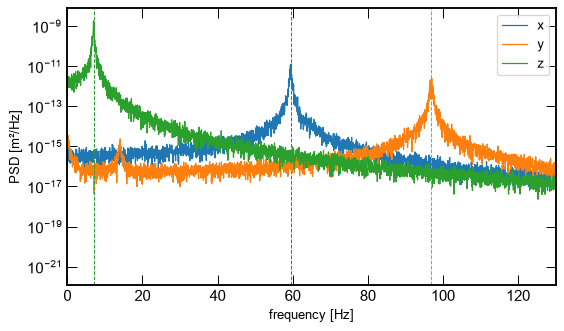

In [9]:
sim_trap = Trap(fields=trap.fields, particle=sphere, gas=Gas(P=4e-3 * mbar, T=295.0), β=0.0,
                linearisation_point=rep['equilibrium'])
X0 = np.r_[rep['equilibrium'], 0, 0, 0]
t0 = time.time()
sim = FreeSpaceSimulation(trap=sim_trap, num_samples=200_000, Δt=0.5e-3, X0=X0, seed=2018)
sim.simulate_dynamics()
print(f'{sim.num_samples} steps in {time.time() - t0:.0f} s, backend {sim.backend_used}, Γ/2π = {sim_trap.Γx / Hz:.3f} Hz')
fig, ax = plt.subplots(figsize=(7, 4))
peaks = []
for axis, colour, Ω in zip('xyz', ('C0', 'C1', 'C2'), rep['Ω_axes']):
    f, S = welch(sim.traces[axis].values, fs=1 / sim.Δt, nperseg=2**16)
    ax.semilogy(f, S, color=colour, label=f'{axis}')
    ax.axvline(Ω / Hz, color=colour, ls='--', lw=0.8)
    i = np.argmax(S[1:]) + 1
    a, b, c = np.log(S[i - 1:i + 2])
    peaks.append(f[i] + 0.5 * (a - c) / (a - 2 * b + c) * (f[1] - f[0]))
ax.set_xlim(0, 130)
ax.set_xlabel('frequency [Hz]')
ax.set_ylabel('PSD [m²/Hz]')
ax.legend()
plt.show()
print('PSD peaks [Hz]:', np.round(peaks, 3), ' report:', np.round(rep['Ω_axes'] / Hz, 3), ' paper:', ω_paper / Hz)

## Summary

| Check | Published | levisim | Verdict |
|---|---|---|---|
| levitation $B\,\partial B/\partial y$, SiO₂ (Houlton Table 1) | 2400 T²/m | 2403.5 T²/m | agrees (table rounded); H₂O, GaN, graphite, mineral oil within 0.4 % |
| Hsu (2016) model, published coefficients, diamond | (104, 130, 9.6) Hz, −19 μm, ≈ 0.2 T | (106.1, 130.3, 9.56) Hz, −18.87 μm, 0.186 T | agrees within the 2-figure rounding of $a_2$, $a_3$, $a_4$ (χ of diamond assumed) |
| single quadrupole at the stated "∼10⁴ T/m" | $\omega_y/2\pi$ = 96.9 Hz, $\omega_x/2\pi$ = 59.6 Hz | 101.7 Hz (any transverse axis) | order of magnitude right; a pure quadrupole cannot give $\omega_x \ne \omega_y$ |
| three-multipole fit to the frequencies | gradient "∼10⁴ T/m" | 5.8 × 10³ T/m at the field zero, 7.9 × 10³ T/m at the equilibrium; $y_\mathrm{eq}$ = −46.7 μm, $B_\mathrm{eq}$ = 0.30 T; unique from three starts | consistent; the fit itself is exact by construction |
| size independence | stated (Hsu Eq. (7)) | identical to 9 decimals over ±9.6 % in diameter | agrees |
| mass of a 1.54 μm sphere | 3.10 × 10⁻¹⁵ kg measured, (3.4 ± 1.0) × 10⁻¹⁵ expected | 4.21 × 10⁻¹⁵ kg at 2200 kg/m³ | the paper's numbers imply ρ ≈ 1620-1780 kg/m³ (porous or less dense spheres); frequencies depend only on χ/ρ |
| gas damping at 10⁻¹⁰ Torr | 2 × 10⁻⁸ Hz | 0.96 × 10⁻⁸ Hz (ρ = 2200), 1.30 × 10⁻⁸ Hz (ρ from the measured mass) | same order; the paper's gas species, accommodation and ρ are not stated |
| simulated PSD peaks against the stiffness | — | 59.58, 97.02, 6.96 Hz against 59.6, 96.9, 7.01 Hz | x, y within 0.12 %; z 0.7 % low: the thermal axial amplitude (≈ 22 μm rms at 295 K) is not small against the 75 μm field scale, so the anharmonic potential shifts the line |

Not reproduced: the field from the actual pole pieces and SmCo magnets (dimensions not published; a
finite-element or `CuboidMagnet`/`FieldSum` model of the pole tips would be needed, and soft-iron pole
pieces are not uniformly magnetised blocks); the feedback cooling (Figs. 5, 6), which needs the paper's
phase-shifted velocity feedback and detection noise.

In [10]:
print(f'total computation time {time.time() - t_start:.0f} s')

total computation time 12 s
